In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageEnhance, ImageOps
import os

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving Ijazah 1.png to Ijazah 1.png
Saving Ijazah 2.png to Ijazah 2.png
Saving Ijazah 3.png to Ijazah 3.png
Saving Ijazah 4.png to Ijazah 4.png
Saving Ijazah 5.png to Ijazah 5.png
Saving Ijazah 6.png to Ijazah 6.png
Saving Ijazah 7.png to Ijazah 7.png
Saving Ijazah 8.png to Ijazah 8.png
Saving Ijazah 9.png to Ijazah 9.png


In [ ]:
print("Jumlah gambar:", len(uploaded))
print("\nNama file:")

for filename in uploaded.keys():
    print(filename)

Jumlah gambar: 9

Nama file:
Ijazah 1.png
Ijazah 2.png
Ijazah 3.png
Ijazah 4.png
Ijazah 5.png
Ijazah 6.png
Ijazah 7.png
Ijazah 8.png
Ijazah 9.png


In [ ]:
images = {}

for i in range(1, 10):
    filename = [f for f in uploaded.keys()
                if f.lower().startswith(f"ijazah {i}".lower())][0]

    img = cv2.imread(filename)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    images[i] = img

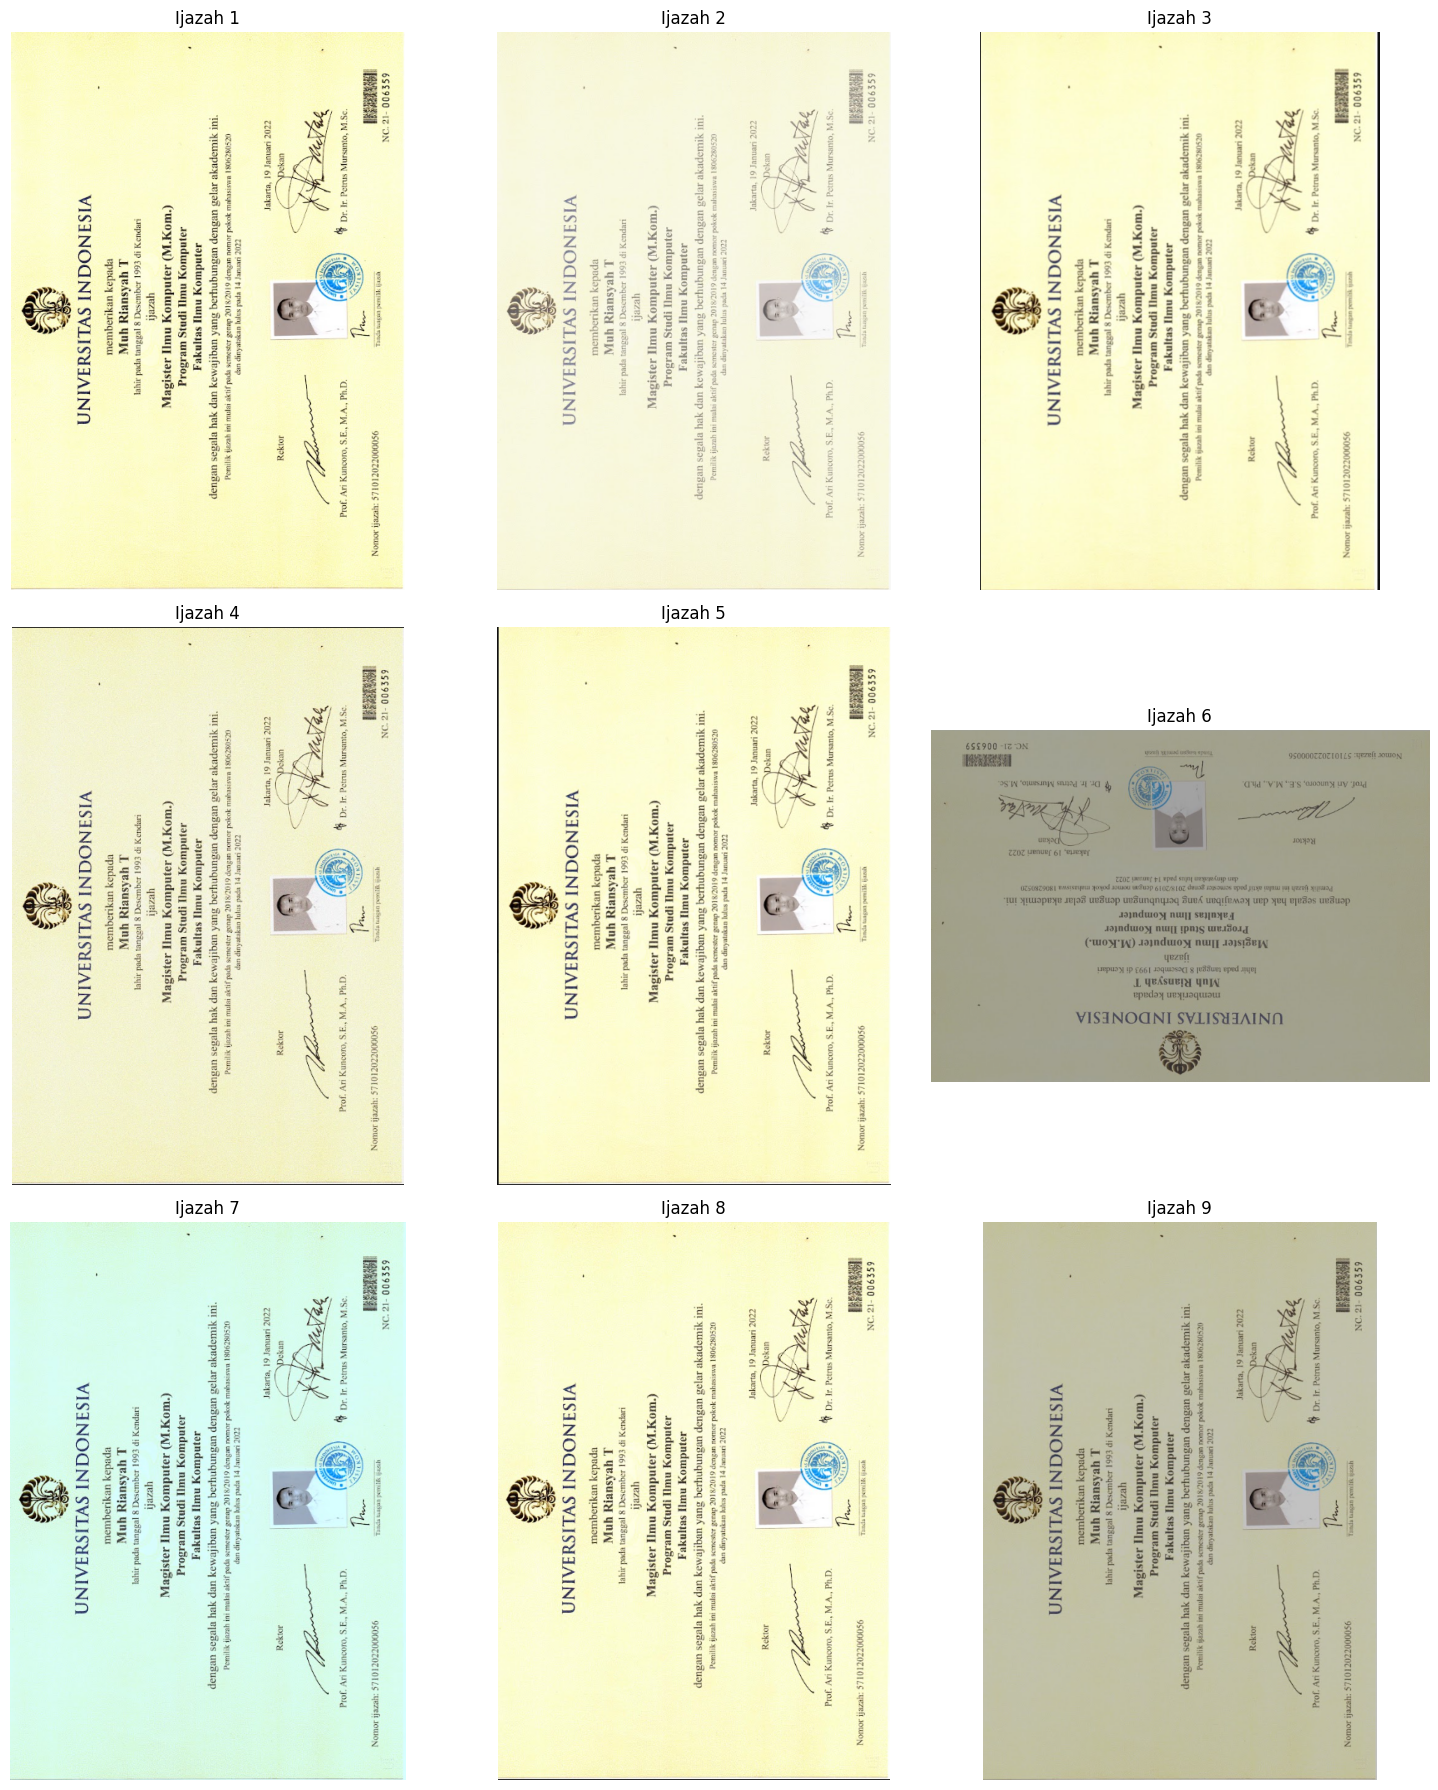

In [ ]:
plt.figure(figsize=(15, 18))

for i in range(1, 10):
    plt.subplot(3, 3, i)
    plt.imshow(images[i])
    plt.title(f"Ijazah {i}")
    plt.axis("off")

plt.tight_layout()
plt.show()

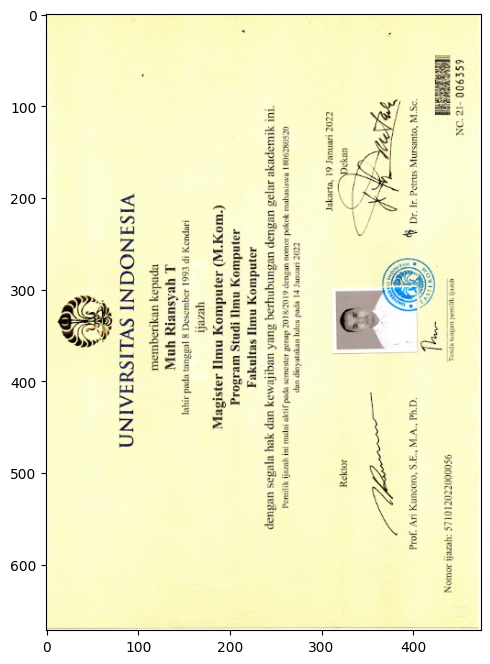

In [ ]:
img = images[1]

plt.figure(figsize=(12, 8))
plt.imshow(img)
plt.axis("on")
plt.show()

In [ ]:
height, width = img.shape[:2]

(width, height)

(474, 672)

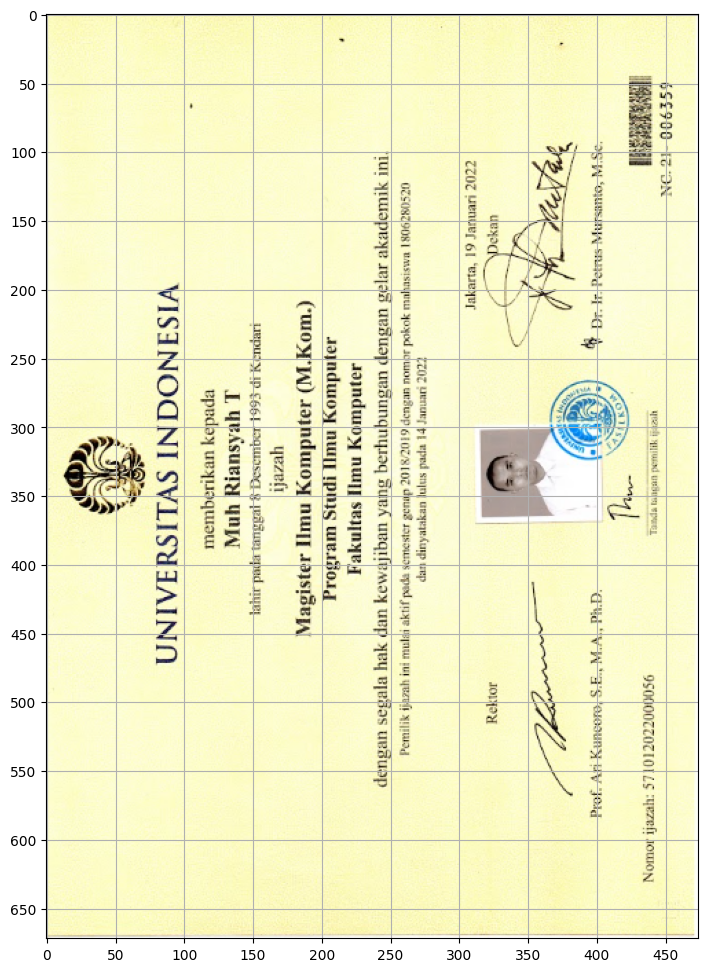

In [ ]:
plt.figure(figsize=(10, 12))

plt.imshow(img)
plt.xticks(range(0, width + 1, 50))
plt.yticks(range(0, height + 1, 50))
plt.grid()

plt.show()

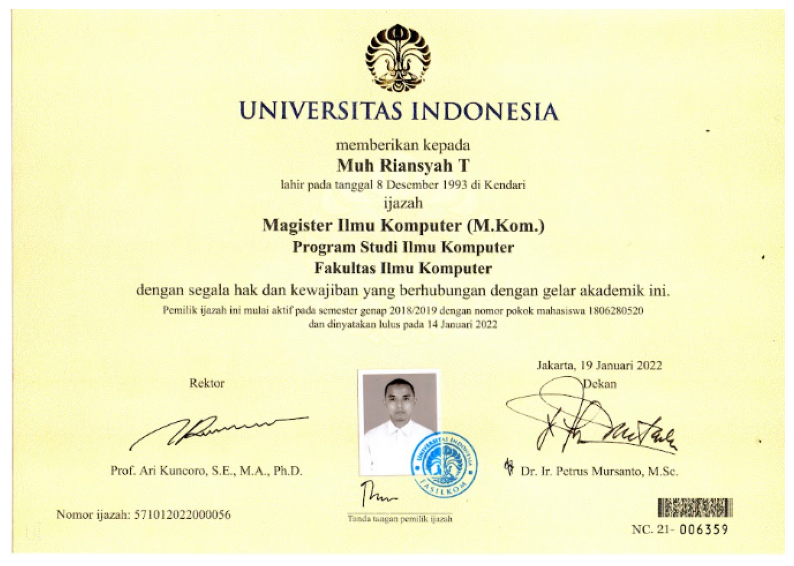

In [ ]:
rotated = cv2.rotate(img, cv2.ROTATE_90_CLOCKWISE)

plt.figure(figsize=(10, 12))
plt.imshow(rotated)
plt.axis("off")
plt.show()

In [ ]:
height_r, width_r = rotated.shape[:2]

(width_r, height_r)

(672, 474)

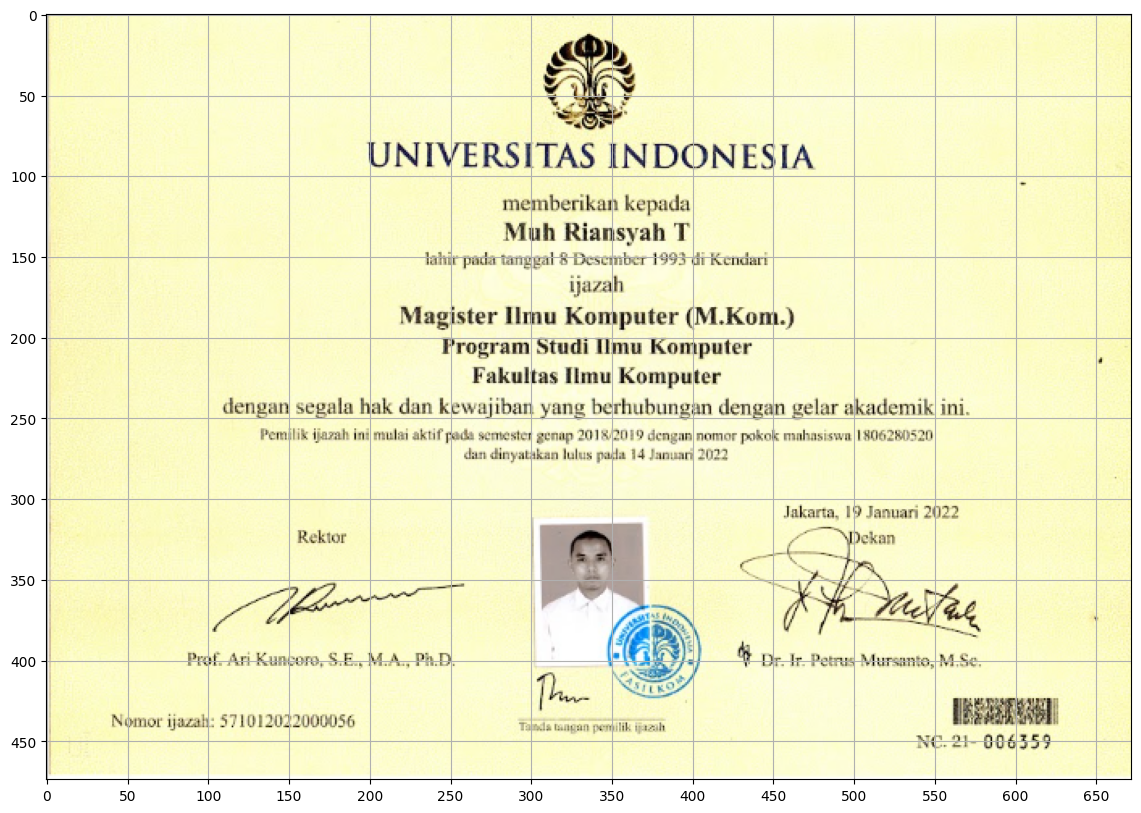

In [ ]:
plt.figure(figsize=(14, 10))

plt.imshow(rotated)
plt.xticks(range(0, width_r + 1, 50))
plt.yticks(range(0, height_r + 1, 50))
plt.grid()

plt.show()

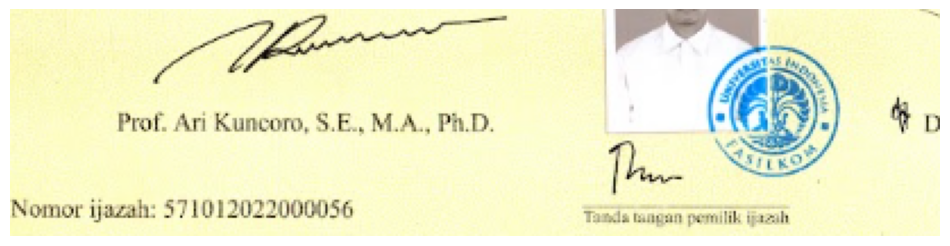

In [ ]:
x1 = 40
y1 = 350
x2 = 450
y2 = 450

crop = rotated[y1:y2, x1:x2]

plt.figure(figsize=(12, 4))
plt.imshow(crop)
plt.axis("off")
plt.show()

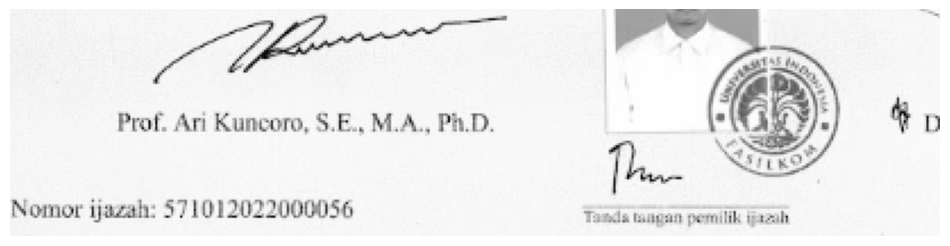

In [ ]:
gray = cv2.cvtColor(crop, cv2.COLOR_RGB2GRAY)

plt.figure(figsize=(12, 4))
plt.imshow(gray, cmap="gray")
plt.axis("off")
plt.show()

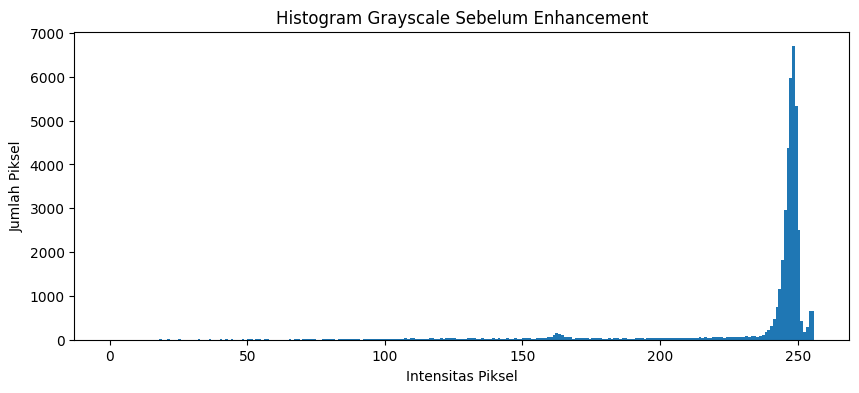

In [ ]:
plt.figure(figsize=(10, 4))

plt.hist(gray.ravel(), bins=256, range=(0, 256))

plt.title("Histogram Grayscale Sebelum Enhancement")
plt.xlabel("Intensitas Piksel")
plt.ylabel("Jumlah Piksel")

plt.show()

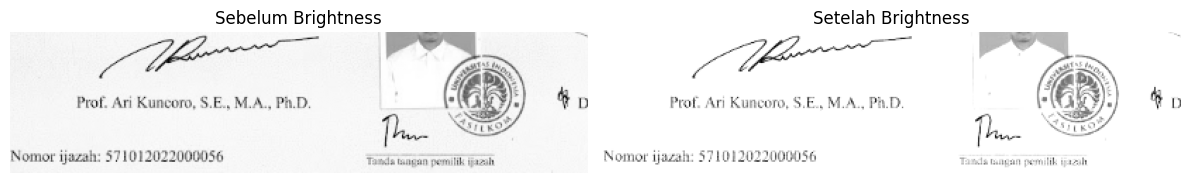

In [ ]:
brightness = cv2.convertScaleAbs(gray, alpha=1.0, beta=30)

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.imshow(gray, cmap="gray")
plt.title("Sebelum Brightness")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(brightness, cmap="gray")
plt.title("Setelah Brightness")
plt.axis("off")

plt.tight_layout()
plt.show()

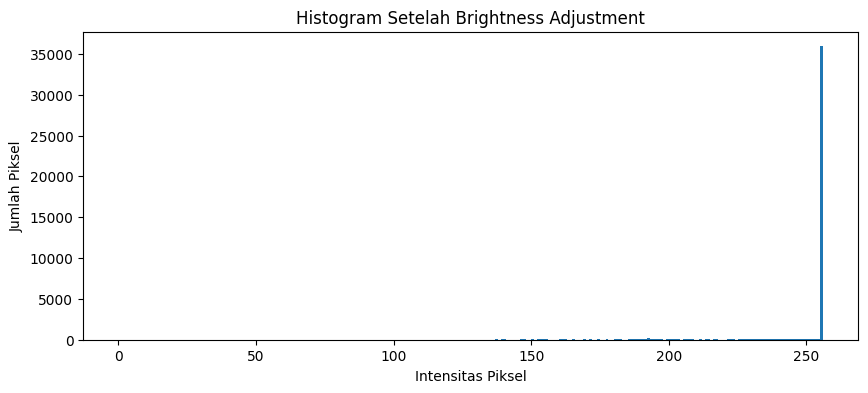

In [ ]:
plt.figure(figsize=(10, 4))

plt.hist(brightness.ravel(), bins=256, range=(0, 256))

plt.title("Histogram Setelah Brightness Adjustment")
plt.xlabel("Intensitas Piksel")
plt.ylabel("Jumlah Piksel")

plt.show()

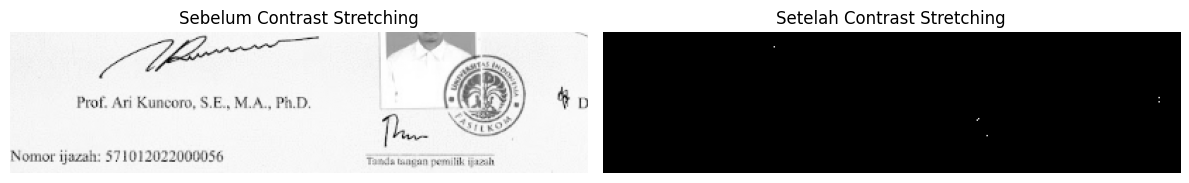

In [ ]:
min_val = np.min(gray)
max_val = np.max(gray)

if max_val > min_val:
    contrast = ((gray - min_val) * 255 / (max_val - min_val)).astype(np.uint8)
else:
    contrast = gray.copy()

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.imshow(gray, cmap="gray")
plt.title("Sebelum Contrast Stretching")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(contrast, cmap="gray")
plt.title("Setelah Contrast Stretching")
plt.axis("off")

plt.tight_layout()
plt.show()

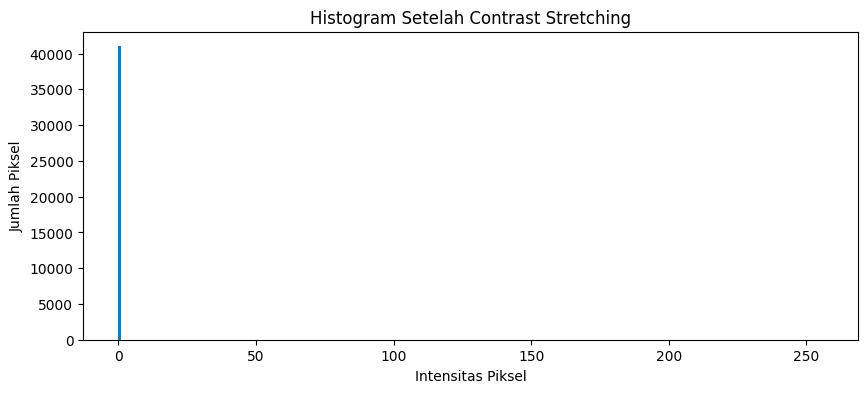

In [ ]:
plt.figure(figsize=(10, 4))

plt.hist(contrast.ravel(), bins=256, range=(0, 256))

plt.title("Histogram Setelah Contrast Stretching")
plt.xlabel("Intensitas Piksel")
plt.ylabel("Jumlah Piksel")

plt.show()

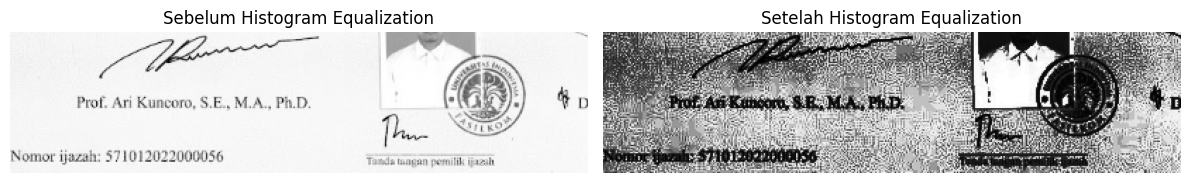

In [ ]:
hist_equalized = cv2.equalizeHist(gray)

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.imshow(gray, cmap="gray")
plt.title("Sebelum Histogram Equalization")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(hist_equalized, cmap="gray")
plt.title("Setelah Histogram Equalization")
plt.axis("off")

plt.tight_layout()
plt.show()

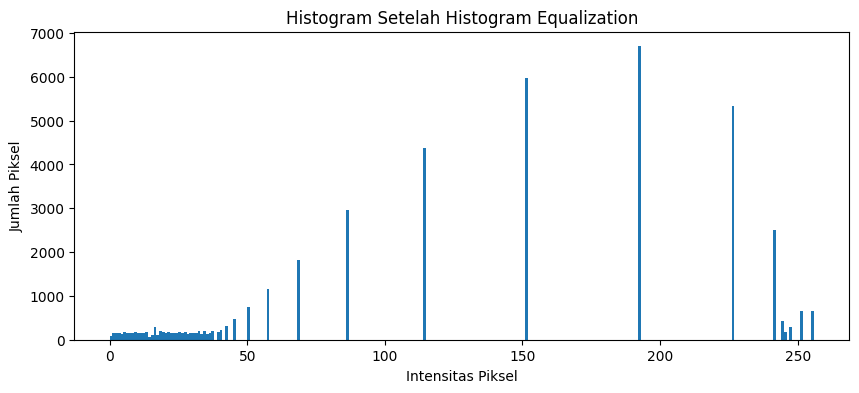

In [ ]:
plt.figure(figsize=(10, 4))

plt.hist(hist_equalized.ravel(), bins=256, range=(0, 256))

plt.title("Histogram Setelah Histogram Equalization")
plt.xlabel("Intensitas Piksel")
plt.ylabel("Jumlah Piksel")

plt.show()

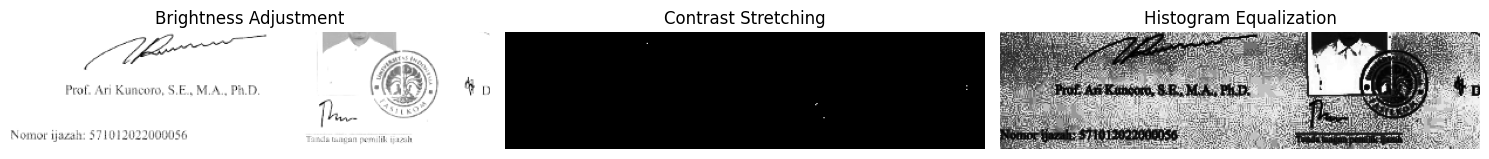

In [ ]:
plt.figure(figsize=(15, 4))

plt.subplot(1, 3, 1)
plt.imshow(brightness, cmap="gray")
plt.title("Brightness Adjustment")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(contrast, cmap="gray")
plt.title("Contrast Stretching")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(hist_equalized, cmap="gray")
plt.title("Histogram Equalization")
plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
!sudo apt-get update -qq
!sudo apt-get install -y tesseract-ocr -qq

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)


In [ ]:
!pip install pytesseract -q

In [ ]:
import pytesseract

In [ ]:
config = "--psm 7 -c tessedit_char_whitelist=0123456789"

ocr_brightness = pytesseract.image_to_string(
    brightness,
    config=config
).strip()

ocr_contrast = pytesseract.image_to_string(
    contrast,
    config=config
).strip()

ocr_equalized = pytesseract.image_to_string(
    hist_equalized,
    config=config
).strip()

{
    "Brightness Adjustment": ocr_brightness,
    "Contrast Stretching": ocr_contrast,
    "Histogram Equalization": ocr_equalized
}

{'Brightness Adjustment': '',
 'Contrast Stretching': '',
 'Histogram Equalization': ''}

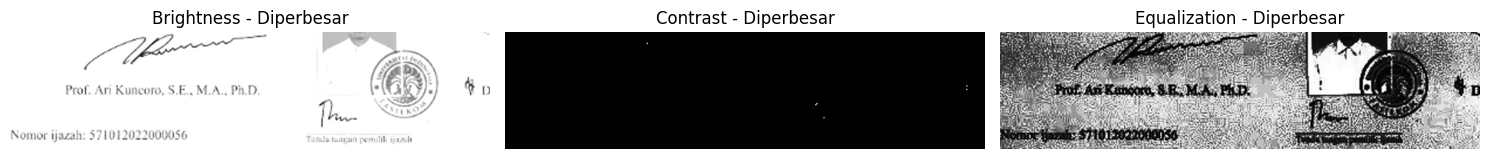

In [ ]:
scale = 4

brightness_ocr = cv2.resize(
    brightness,
    None,
    fx=scale,
    fy=scale,
    interpolation=cv2.INTER_CUBIC
)

contrast_ocr = cv2.resize(
    contrast,
    None,
    fx=scale,
    fy=scale,
    interpolation=cv2.INTER_CUBIC
)

equalized_ocr = cv2.resize(
    hist_equalized,
    None,
    fx=scale,
    fy=scale,
    interpolation=cv2.INTER_CUBIC
)

plt.figure(figsize=(15, 4))

plt.subplot(1, 3, 1)
plt.imshow(brightness_ocr, cmap="gray")
plt.title("Brightness - Diperbesar")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(contrast_ocr, cmap="gray")
plt.title("Contrast - Diperbesar")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(equalized_ocr, cmap="gray")
plt.title("Equalization - Diperbesar")
plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
config = "--psm 7 -c tessedit_char_whitelist=0123456789"

ocr_brightness = pytesseract.image_to_string(
    brightness_ocr,
    config=config
).strip()

ocr_contrast = pytesseract.image_to_string(
    contrast_ocr,
    config=config
).strip()

ocr_equalized = pytesseract.image_to_string(
    equalized_ocr,
    config=config
).strip()

{
    "Brightness Adjustment": ocr_brightness,
    "Contrast Stretching": ocr_contrast,
    "Histogram Equalization": ocr_equalized
}

{'Brightness Adjustment': '',
 'Contrast Stretching': '7',
 'Histogram Equalization': ''}

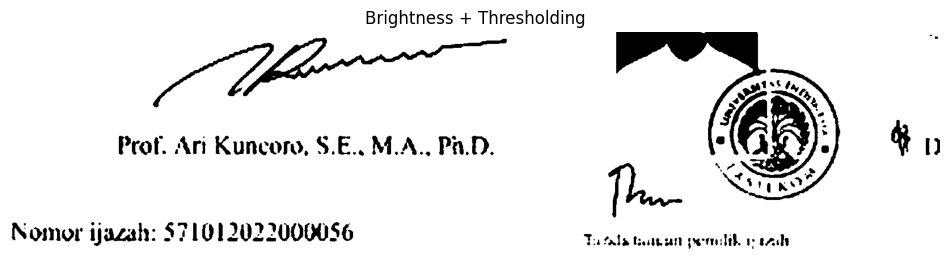

In [ ]:
_, brightness_binary = cv2.threshold(
    brightness_ocr,
    0,
    255,
    cv2.THRESH_BINARY + cv2.THRESH_OTSU
)

plt.figure(figsize=(12, 4))

plt.imshow(brightness_binary, cmap="gray")
plt.title("Brightness + Thresholding")
plt.axis("off")

plt.show()